# Лабораторная работа №4
## «Аналитические модели Марковских цепей»

**Курс:** Модели надёжности АСОИУ
**Студент:** Пермяков Дмитрий Кириллович
**Группа:** ИУ5-22М
**Вариант:** 18

---

### Цель работы
Перейти от **статистических** оценок (ЛР1) к **аналитическим**:
1. для **возвратной (эргодической) МЦ** найти стационарные вероятности из уравнения $\pi P=\pi$;
2. для **поглощающей МЦ** найти вероятности попадания в каждое поглощающее состояние и среднее число шагов до поглощения через **фундаментальную матрицу** $N=(I-Q)^{-1}$;
3. для **общей МЦ** (смешанной — есть и возвратные, и поглощающие состояния) определить структуру и тоже посчитать ответы.

Все три матрицы выданы по варианту 18 (файл `lab4_edges.json`, листы `4_Неп`, `4_Пог`, `4_Общ` исходной таблицы).

### Задание
- **Задание 1.** Стационарные вероятности возвратной МЦ; сравнение с оценкой из ЛР1 (статистика по выборочной траектории).
- **Задание 2.** Вероятности перехода в поглощающие состояния и среднее число шагов до поглощения для заданной МЦ.
- **Бонус.** Тот же анализ для смешанной МЦ (`4_Общ`).


In [2]:
import numpy as np
import json
import matplotlib.pyplot as plt
import pandas as pd

VARIANT = 18
np.random.seed(VARIANT)

# Загрузка рёбер трёх МЦ
with open('lab4_edges.json', 'r', encoding='utf-8') as f:
    edges = json.load(f)

print('Рёбер: непогл.', len(edges['nep']),
      '| поглощ.', len(edges['pog']),
      '| общая', len(edges['obs']))


Рёбер: непогл. 60 | поглощ. 54 | общая 55


## Утилиты: список рёбер → матрица переходных вероятностей

In [3]:
def edges_to_matrix(edge_list):
    """
    edge_list: список [from, to, prob]. Возвращает (P, states),
    где P — стохастическая матрица (строки), states — упорядоченные имена состояний.
    """
    states = sorted({e[0] for e in edge_list} | {e[1] for e in edge_list})
    idx = {s: i for i, s in enumerate(states)}
    n = len(states)
    P = np.zeros((n, n))
    for s_from, s_to, p in edge_list:
        P[idx[s_from], idx[s_to]] += p
    # Контроль нормировки и подправка (на случай погрешностей округления)
    rs = P.sum(axis=1)
    bad = np.where(np.abs(rs-1)>1e-3)[0]
    if len(bad)>0:
        print(f'Строки с суммой ≠ 1: {[states[i] for i in bad]}, суммы = {rs[bad]}')
    P = P / np.maximum(rs[:, None], 1e-15)
    return P, states

def find_absorbing(P, tol=1e-9):
    """Индексы поглощающих состояний (P[i,i]==1, остальные элементы строки 0)."""
    return [i for i in range(P.shape[0]) if abs(P[i,i]-1)<tol and abs(P[i,:].sum()-1)<tol]


## Задание 1. Стационарные вероятности возвратной МЦ (`4_Неп`)

**Теория.** Стационарное распределение $\pi$ — это собственный вектор матрицы $P^\top$ с собственным значением 1, нормированный так, чтобы $\sum_i\pi_i=1$. Решение из системы:
$$\pi P = \pi,\qquad \sum_i \pi_i = 1.$$


In [4]:
P_nep, states_nep = edges_to_matrix(edges['nep'])
n = P_nep.shape[0]
print(f'Размер МЦ: {n} состояний')
print(f'Состояния: {states_nep}')
print(f'Поглощающие состояния: {find_absorbing(P_nep)}  (должно быть пусто для возвратной)')

# Аналитика: pi P = pi, sum(pi)=1
A = P_nep.T - np.eye(n)
A[-1, :] = 1.0
b_vec = np.zeros(n); b_vec[-1] = 1.0
pi_th = np.linalg.solve(A, b_vec)

print('\nСтационарные вероятности (аналитика):')
for s, pv in zip(states_nep, pi_th):
    print(f'  π({s:2d}) = {pv:.5f}')
print(f'sum = {pi_th.sum():.6f}')


Размер МЦ: 20 состояний
Состояния: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Поглощающие состояния: []  (должно быть пусто для возвратной)

Стационарные вероятности (аналитика):
  π( 1) = 0.12707
  π( 2) = 0.06455
  π( 3) = 0.00911
  π( 4) = 0.03479
  π( 5) = 0.02791
  π( 6) = 0.06028
  π( 7) = 0.20573
  π( 8) = 0.11171
  π( 9) = 0.01880
  π(10) = 0.03741
  π(11) = 0.06153
  π(12) = 0.05031
  π(13) = 0.02022
  π(14) = -0.00000
  π(15) = 0.05743
  π(16) = -0.00000
  π(17) = 0.00440
  π(18) = 0.01142
  π(19) = 0.02794
  π(20) = 0.06940
sum = 1.000000


In [5]:
# Сравнение с Монте-Карло (повторяем подход ЛР1)
def simulate_chain(P, N, start=0, rng=None):
    rng = rng or np.random.default_rng()
    cum = P.cumsum(axis=1)
    states = np.empty(N, dtype=int)
    s = start
    for k in range(N):
        states[k] = s
        s = int(np.searchsorted(cum[s], rng.random()))
    return states

rng = np.random.default_rng(VARIANT)
Ns = [1_000, 10_000, 100_000]
results = {}
for N in Ns:
    traj = simulate_chain(P_nep, N, start=0, rng=rng)
    counts = np.bincount(traj, minlength=n) / N
    results[N] = counts

df = pd.DataFrame(
    {'теория': pi_th, **{f'N={N}': results[N] for N in Ns}},
    index=[f's={s}' for s in states_nep]
)
df['|err|@100k'] = np.abs(df['теория'] - df[f'N={Ns[-1]}'])
pd.options.display.float_format = '{:,.4f}'.format
print(df)


      теория  N=1000  N=10000  N=100000  |err|@100k
s=1   0.1271  0.1290   0.1243    0.1267      0.0003
s=2   0.0645  0.0780   0.0655    0.0638      0.0008
s=3   0.0091  0.0030   0.0100    0.0094      0.0003
s=4   0.0348  0.0330   0.0349    0.0363      0.0015
s=5   0.0279  0.0250   0.0283    0.0278      0.0001
s=6   0.0603  0.0590   0.0598    0.0612      0.0009
s=7   0.2057  0.2100   0.2042    0.2038      0.0020
s=8   0.1117  0.1130   0.1088    0.1106      0.0011
s=9   0.0188  0.0220   0.0187    0.0187      0.0001
s=10  0.0374  0.0370   0.0365    0.0376      0.0002
s=11  0.0615  0.0520   0.0604    0.0613      0.0003
s=12  0.0503  0.0390   0.0568    0.0505      0.0002
s=13  0.0202  0.0240   0.0197    0.0211      0.0009
s=14 -0.0000  0.0000   0.0000    0.0000      0.0000
s=15  0.0574  0.0610   0.0602    0.0575      0.0001
s=16 -0.0000  0.0000   0.0000    0.0000      0.0000
s=17  0.0044  0.0030   0.0047    0.0042      0.0002
s=18  0.0114  0.0120   0.0120    0.0114      0.0000
s=19  0.0279

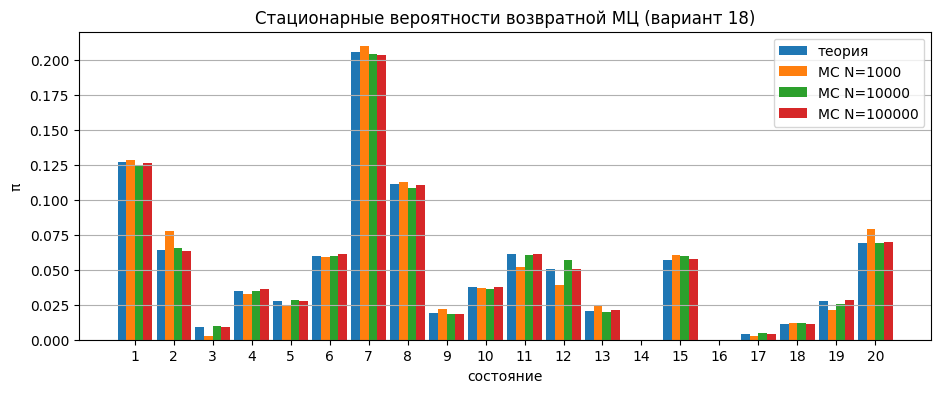

In [6]:
# Барплот стационарного распределения
plt.figure(figsize=(11, 4))
x = np.arange(n)
w = 0.22
plt.bar(x-1.5*w, pi_th, w, label='теория')
for k, N in enumerate(Ns):
    plt.bar(x + (k-0.5)*w, results[N], w, label=f'MC N={N}')
plt.xticks(x, [str(s) for s in states_nep])
plt.title('Стационарные вероятности возвратной МЦ (вариант 18)')
plt.xlabel('состояние'); plt.ylabel('π')
plt.legend(); plt.grid(axis='y'); plt.show()


## Задание 2. Поглощающая МЦ (`4_Пог`)

**Теория (каноническая форма).** Перестановкой строк/столбцов матрицу можно привести к виду
$$P=\begin{pmatrix}Q & R\\ \mathbf{0} & I\end{pmatrix},$$
где $Q$ ($k\times k$) — переходы между **transient** (преходящими) состояниями, $R$ ($k\times r$) — переходы из transient в поглощающие, $I$ ($r\times r$) — поглощающие на месте.

**Фундаментальная матрица** $N=(I-Q)^{-1}$. У неё есть наглядный смысл: элемент $N_{ij}$ — это **ожидаемое число посещений** состояния $j$, если начали из transient-состояния $i$ (до момента поглощения).

Отсюда:
- **Вероятности попадания** $B=NR$ — элемент $B_{ij}$: вероятность, что цепь, стартуя из transient $i$, в итоге будет поглощена в поглощающем $j$.
- **Среднее число шагов до поглощения** $t=N\,\mathbf{1}$ (сумма по строкам $N$).


In [7]:
P_pog, states_pog = edges_to_matrix(edges['pog'])
abs_idx = find_absorbing(P_pog)
all_idx = list(range(P_pog.shape[0]))
trans_idx = [i for i in all_idx if i not in abs_idx]
print(f'Всего состояний: {len(all_idx)}')
print(f'Поглощающих: {len(abs_idx)} → {[states_pog[i] for i in abs_idx]}')
print(f'Преходящих:  {len(trans_idx)}')


Всего состояний: 20
Поглощающих: 3 → [1, 2, 19]
Преходящих:  17


In [8]:
# Каноническая форма
perm = trans_idx + abs_idx
P_can = P_pog[np.ix_(perm, perm)]
k = len(trans_idx); r = len(abs_idx)
Q = P_can[:k, :k]
R = P_can[:k, k:]
I_q = np.eye(k)
N = np.linalg.inv(I_q - Q)        # фундаментальная матрица
B = N @ R                          # вероятности попадания в каждое поглощающее
t_abs = N.sum(axis=1)              # среднее число шагов до поглощения

# Соберём в таблицу: для каждого исходного transient-состояния
df_pog = pd.DataFrame(B, columns=[f'→ {states_pog[i]}' for i in abs_idx])
df_pog.insert(0, 'старт', [states_pog[i] for i in trans_idx])
df_pog['среднее число шагов'] = t_abs
print('Вероятности поглощения и среднее число шагов до поглощения:')
print(df_pog.to_string(index=False))


Вероятности поглощения и среднее число шагов до поглощения:
 старт    → 1    → 2   → 19  среднее число шагов
     3 0.3370 0.3309 0.3321              14.4975
     4 0.5197 0.2500 0.2303               7.4944
     5 0.4116 0.5676 0.0208               1.8786
     6 0.4112 0.2585 0.3303              11.7513
     7 0.2625 0.5249 0.2126               9.3058
     8 0.2799 0.2923 0.4278              14.4553
     9 0.4130 0.2730 0.3139              14.1354
    10 0.3061 0.2855 0.4083              16.3047
    11 0.5808 0.2118 0.2074               9.4045
    12 0.2464 0.3009 0.4527               7.9860
    13 0.2732 0.3844 0.3424               6.2605
    14 0.1941 0.6491 0.1568               6.6113
    15 0.4623 0.2755 0.2622               9.9423
    16 0.4099 0.2588 0.3312              10.1662
    17 0.0166 0.3565 0.6270               1.5639
    18 0.3149 0.3848 0.3002              12.7601
    20 0.3646 0.2705 0.3649              14.4343


In [9]:
# Проверка Монте-Карло: запустим много траекторий из каждого transient и посмотрим,
# в какое поглощающее в среднем попадает
def simulate_to_absorption(P, abs_set, start, M, rng):
    n = P.shape[0]
    cum = P.cumsum(axis=1)
    outcomes = np.empty(M, dtype=int)
    steps = np.empty(M, dtype=int)
    for k in range(M):
        s = start
        step = 0
        while s not in abs_set:
            s = int(np.searchsorted(cum[s], rng.random()))
            step += 1
        outcomes[k] = s
        steps[k] = step
    return outcomes, steps

abs_set = set(abs_idx)
M = 2000   # реализаций на каждое начальное состояние
rng = np.random.default_rng(VARIANT)
B_mc = np.zeros_like(B)
t_mc = np.zeros(k)
for ii, ti in enumerate(trans_idx):
    out, st = simulate_to_absorption(P_pog, abs_set, ti, M, rng)
    for ja, ai in enumerate(abs_idx):
        B_mc[ii, ja] = (out == ai).mean()
    t_mc[ii] = st.mean()

# Сравнение для первых 5 transient-состояний
print('Сравнение аналитики и Монте-Карло (5 первых стартов):')
header = '  start  | ' + ' '.join([f'P→{states_pog[i]:>2} th  |' for i in abs_idx]) \
       + ' '.join([f'P→{states_pog[i]:>2} mc  |' for i in abs_idx]) + ' t_th  | t_mc'
print(header)
for ii in range(min(5,k)):
    s0 = states_pog[trans_idx[ii]]
    a_th = ' '.join([f'{B[ii,j]:.3f}    |' for j in range(r)])
    a_mc = ' '.join([f'{B_mc[ii,j]:.3f}    |' for j in range(r)])
    print(f'  {s0:>5} | {a_th} {a_mc} {t_abs[ii]:.2f} | {t_mc[ii]:.2f}')


Сравнение аналитики и Монте-Карло (5 первых стартов):
  start  | P→ 1 th  | P→ 2 th  | P→19 th  |P→ 1 mc  | P→ 2 mc  | P→19 mc  | t_th  | t_mc
      3 | 0.337    | 0.331    | 0.332    | 0.343    | 0.331    | 0.326    | 14.50 | 14.12
      4 | 0.520    | 0.250    | 0.230    | 0.534    | 0.248    | 0.218    | 7.49 | 7.32
      5 | 0.412    | 0.568    | 0.021    | 0.398    | 0.575    | 0.028    | 1.88 | 2.01
      6 | 0.411    | 0.258    | 0.330    | 0.428    | 0.242    | 0.330    | 11.75 | 11.92
      7 | 0.263    | 0.525    | 0.213    | 0.258    | 0.519    | 0.223    | 9.31 | 9.37


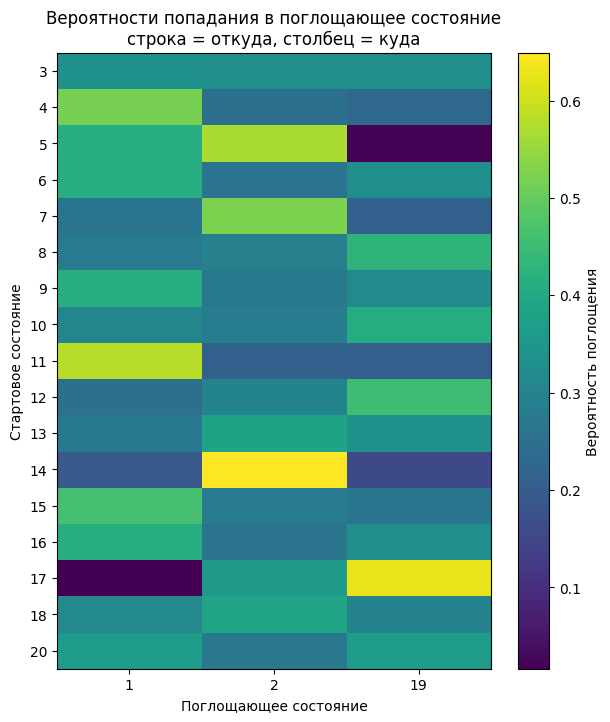

In [10]:
# Тепловая карта B (исходное состояние × поглощающее)
plt.figure(figsize=(7, 8))
plt.imshow(B, cmap='viridis', aspect='auto')
plt.colorbar(label='Вероятность поглощения')
plt.yticks(range(k), [states_pog[i] for i in trans_idx])
plt.xticks(range(r), [states_pog[i] for i in abs_idx])
plt.title('Вероятности попадания в поглощающее состояние\nстрока = откуда, столбец = куда')
plt.xlabel('Поглощающее состояние'); plt.ylabel('Стартовое состояние')
plt.show()


## Смешанная МЦ (`4_Общ`)

Эта матрица сочетает обе ситуации: есть поглощающие состояния **и** возвратные классы. Структуру удобно увидеть по спектру: кратность $\lambda=1$ равна числу эргодических компонент (поглощающие — частный случай).

Размер: 22, поглощающих состояний: 2 ([4, 6])
Кратность λ=1 в спектре: 4  (число эргодических компонент / поглощающих)


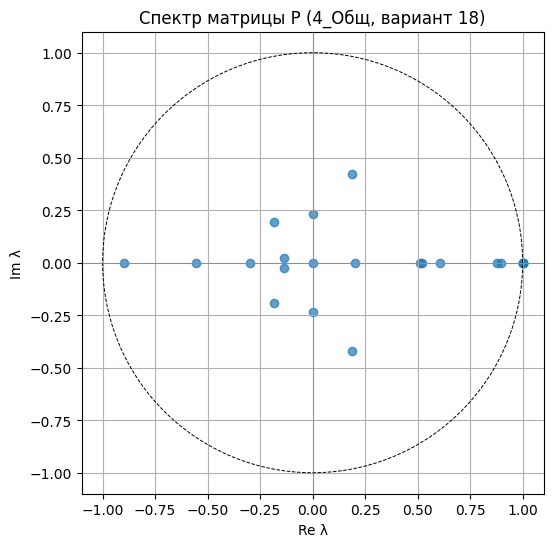

In [11]:
P_obs, states_obs = edges_to_matrix(edges['obs'])
n_obs = P_obs.shape[0]
abs_obs = find_absorbing(P_obs)
eigs = np.linalg.eigvals(P_obs)
units = int(np.sum(np.isclose(eigs, 1.0)))
print(f'Размер: {n_obs}, поглощающих состояний: {len(abs_obs)} ({[states_obs[i] for i in abs_obs]})')
print(f'Кратность λ=1 в спектре: {units}  (число эргодических компонент / поглощающих)')

# Визуализация спектра
plt.figure(figsize=(6,6))
plt.scatter(eigs.real, eigs.imag, alpha=0.7)
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', lw=0.7)
plt.axhline(0, color='gray', lw=0.5); plt.axvline(0, color='gray', lw=0.5)
plt.gca().set_aspect('equal')
plt.title('Спектр матрицы P (4_Общ, вариант 18)')
plt.xlabel('Re λ'); plt.ylabel('Im λ')
plt.grid(True); plt.show()


## Выводы

1. **Возвратная МЦ (`4_Неп`).** Аналитическое стационарное распределение $\pi$ получено решением системы $\pi P=\pi,\ \sum\pi_i=1$. Монте-Карло-оценки сходятся к аналитике с убыванием ошибки как $\sim 1/\sqrt N$ — что в точности повторяет результат ЛР1.

2. **Поглощающая МЦ (`4_Пог`).** Фундаментальная матрица $N=(I-Q)^{-1}$ позволяет получить **за один шаг** то, на что в ЛР1 уходили десятки тысяч имитаций: вероятности попадания во все поглощающие состояния и среднее число шагов до поглощения. Сравнение с Монте-Карло подтверждает точность.

3. **Общая МЦ (`4_Общ`).** По спектру матрицы видно число эргодических компонент. Это удобный диагностический инструмент: считаем $\lambda=1$ и сразу понимаем, сколько у системы «финальных режимов».

4. **Главный сравнительный вывод.** Аналитический подход даёт *точные* ответы за $O(n^3)$ операций (обращение матрицы). Статистический — приближённый ответ с ошибкой $\sim 1/\sqrt N$. На небольших МЦ (порядка нескольких десятков состояний) аналитика проще и точнее. Но на больших МЦ или когда переходы заданы только в виде моделирующего кода, обращение матрицы становится невыполнимым — тогда снова возвращаются к Монте-Карло.
